|                |   |
:----------------|---|
| **Nombre**     |  David Farias Rivera |
| **Fecha**      |  19/10/2026 |
| **Expediente** | 754381  | 

Queremos predecir si una persona tiene enfermedad cardiaca usando una red neuronal de tres capas, y con GridSearch vamos a buscar cuántas neuronas conviene poner en cada capa.

In [5]:
import pandas as pd # Importamos pandas para leer la tabla

data = pd.read_csv("/Users/david/Downloads/Heart Prediction Quantum Dataset.csv", header=0) # Cargamos el dataset del corazon
data.head() # Vemos las primeras filas

,Age,Gender,BloodPressure,Cholesterol,HeartRate,HeartDisease
0,68,Hombre,105.00,191,107,1
1,58,Mujer,97.00,249,89,0
2,44,Mujer,93.00,190,82,1
3,72,Hombre,93.00,183,101,1
4,37,Mujer,145.00,166,103,1


Limpiamos los datos igual que en el Lab R3, porque BloodPressure viene como texto y Gender viene escrito de muchas formas.

In [ ]:
data['BloodPressure'] = data['BloodPressure'].str.replace(',', '.') # Cambiamos la coma decimal por punto
data['BloodPressure'] = data['BloodPressure'].astype(float) # Convertimos la presion a numero con punto decimal

gender = data['Gender'].str.lower().str.rstrip(" }{") # Pasamos todo a minusculas y quitamos espacios y llaves que sobran
gender[gender == 'ombre'] = 'hombre' # Corregimos el typo de la h
gender = gender.map({'hombre': 1, 'mujer': 0}) # Hombre es 1 y mujer es 0
data['Gender'] = gender.astype(int) # Lo guardamos como entero en la tabla

data = data.drop_duplicates() # Quitamos duplicados si hay
data = data.dropna() # Quitamos faltantes si hay
data.info() # Revisamos que ya todo sea numerico

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Age            500 non-null    int64  
 1   Gender         500 non-null    int64  
 2   BloodPressure  500 non-null    float64
 3   Cholesterol    500 non-null    int64  
 4   HeartRate      500 non-null    int64  
 5   HeartDisease   500 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 23.6 KB


Separamos las variables. En x van los factores de la persona y en y si tiene o no enfermedad cardiaca. Dejamos el 25% de los datos para el test.

In [7]:
from sklearn.model_selection import train_test_split # Importamos la funcion para dividir los datos

x = data[['Age', 'Gender', 'BloodPressure', 'Cholesterol', 'HeartRate']] # Estas son nuestras variables de entrada
y = data['HeartDisease'] # Esto es lo que queremos predecir

Xtrain, Xtest, ytrain, ytest = train_test_split(x, y, random_state=42) # Dividimos en train y test con la misma semilla de siempre

Armamos el modelo como un pipeline. Primero escalamos las variables porque la red neuronal es sensible a las escalas y luego va la red con tres capas ocultas.

In [8]:
from sklearn.preprocessing import StandardScaler # Importamos el escalador
from sklearn.neural_network import MLPClassifier # Importamos la red neuronal para clasificar
from sklearn.pipeline import make_pipeline # Importamos el pipeline

scaler = StandardScaler() # Creamos el escalador
mlp = MLPClassifier(max_iter=5000, random_state=42) # Creamos la red con 5000 iteraciones para que todas las redes alcancen a converger
model = make_pipeline(scaler, mlp) # Primero escala y luego entra a la red

Ahora hacemos el GridSearch con 5 folds. Probamos de 5 a 15 neuronas en la capa 1, de 10 a 20 en la capa 2 y de 5 a 10 en la capa 3. El fit se hace solo con el train.

In [9]:
from sklearn.model_selection import GridSearchCV # Importamos la busqueda de hiperparametros

params_list = [] # Aqui vamos a guardar todas las combinaciones de capas
for c1 in range(5, 16): # Neuronas de la capa 1, de 5 a 15
    for c2 in range(10, 21): # Neuronas de la capa 2, de 10 a 20
        for c3 in range(5, 11): # Neuronas de la capa 3, de 5 a 10
            hidden = (int(c1), int(c2), int(c3)) # Armamos la red con las neuronas de cada capa
            params_list.append(hidden) # Guardamos esa red en la lista

print("Combinaciones =", len(params_list)) # Vemos cuantas redes vamos a probar

param_grid = {'mlpclassifier__hidden_layer_sizes': params_list} # Le pasamos todas las redes al grid
grid = GridSearchCV(model, param_grid, cv=5, n_jobs=-1) # Definimos la busqueda con Kfolds = 5 y usando todos los nucleos

%time grid.fit(Xtrain, ytrain) # Ejecutamos la busqueda solo sobre el train
print(grid.best_params_) # Imprimimos la mejor combinacion de capas
print("Accuracy en validacion =", round(grid.best_score_, 3)) # Promedio de los 5 folds de la mejor red

Combinaciones = 726
CPU times: user 2.76 s, sys: 486 ms, total: 3.25 s
Wall time: 2min
{'mlpclassifier__hidden_layer_sizes': (6, 14, 5)}
Accuracy en validacion = 0.787


Tomamos la mejor red que encontró el GridSearch y la probamos con el test, que el modelo nunca vio.

In [10]:
model = grid.best_estimator_ # Nos quedamos con la mejor red
yfit = model.predict(Xtest) # Predecimos sobre el test
print("Accuracy en test =", round(model.score(Xtest, ytest), 3)) # Vemos que tanto acertamos en el test

Accuracy en test = 0.744


In [11]:
from sklearn.metrics import classification_report # Importamos el reporte de clasificacion
print(classification_report(ytest, yfit, target_names=['Sano', 'Enfermo'])) # Precision, recall y f1 para cada clase

              precision    recall  f1-score   support

        Sano       0.70      0.65      0.67        51
     Enfermo       0.77      0.81      0.79        74

    accuracy                           0.74       125
   macro avg       0.74      0.73      0.73       125
weighted avg       0.74      0.74      0.74       125



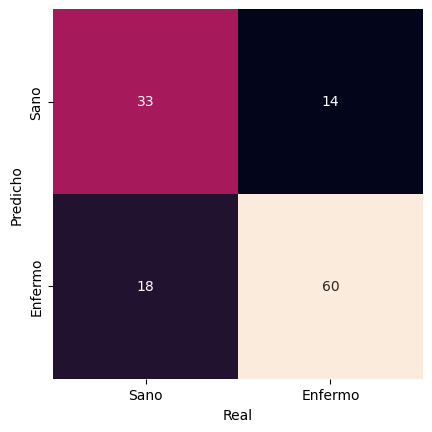

In [12]:
import matplotlib.pyplot as plt # Importamos matplotlib para graficar
import seaborn as sns # Importamos seaborn para el heatmap
from sklearn.metrics import confusion_matrix # Importamos la matriz de confusion

mat = confusion_matrix(ytest, yfit) # Calculamos la matriz de confusion
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False, xticklabels=['Sano', 'Enfermo'], yticklabels=['Sano', 'Enfermo']) # Graficamos la matriz
plt.xlabel('Real') # Eje x con los valores reales
plt.ylabel('Predicho') # Eje y con lo que predijo el modelo
plt.show() # Mostramos la grafica

La mejor red quedó con 6, 14 y 5 neuronas en sus tres capas. En la validación cruzada acertó el 78.7% y en el test, que nunca vio, el 74.4%. La diferencia es chica, así que el modelo no se está sobreajustando mucho, y le va mejor detectando a los enfermos que a los sanos.

## References

1. Scikit-learn developers. (n.d.). sklearn.neural_network.MLPClassifier. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

2. Scikit-learn developers. (n.d.). sklearn.model_selection.GridSearchCV. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

3. Garg, S. (n.d.). Heart Prediction Dataset (Quantum). Kaggle. https://www.kaggle.com/datasets/shantanugarg274/heart-prediction-dataset-quantum